# Lab 04: Classifying satellite image patches with an ANN

## Task 1:

**Data:** Sentinel-2 L2A, acquired on 23.10.2026, bands B02 (blue), B03 (green), B04 (red) and B08 (near-infrared), exported from the Copernicus Browser as 16-bit TIFF files at 10 m resolution. Six locations were downloaded, each covering only one land cover type:

Forest: Puszcza Niepołomicka, Opole region, Lubliniec region

Urban: Katowice, Warsaw, Kraków

## Question 1: The task as a function

The input is a patch of the image: an array of shape (height * width * 4 bands) containing the pixel values. The output is a single number between 0 and 1, interpreted as the probability that the patch shows an urban area. If it is above 0.5, the patch is classified as urban, otherwise as forest.

We do not know this function explicitly, but we have many examples of its inputs and outputs: patches with known labels. Since a neural network can approximate any function given enough examples (universal approximation theorem), it can be trained to learn this mapping from the data. The same function can also be built differently: instead of raw pixels, the input can be a few features describing the patch, such as the mean and standard deviation of each band.

## Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install rasterio -q

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import tensorflow as tf
from pathlib import Path

Mounted at /content/drive


In [2]:
DATA = Path("/content/drive/MyDrive/ml_lab4_data")
BANDS = ["B02", "B03", "B04", "B08"]

PATCH = 32
STRIDE = 16 # half of the overlap
MAX_PATCHES = 500
AUGMENT = True
TEST_LOCATIONS = ["forest_lubliniec", "urban_krakow"]   # never used for training
SEED = 42

The patch size was reduced from the suggested 200 * 200 to 32 * 32 pixels. A 200 * 200 patch covers 2 * 2 km, so only a handful of such patches would fit into each location, which is far too few examples to train a neural network. Smaller patches give hundreds of examples per location while still containing enough spatial context (320 * 320 m) to recognize forest or urban structure.

One forest and one urban location are kept aside as the test set and are never used for training. Since neighbouring patches overlap and are very similar, splitting randomly would put almost identical patches into both sets and give an overly optimistic result. Testing on completely different locations shows whether the network really learned to distinguish forest from urban areas.

## Loading the data

In [4]:
def load_location(folder):
    layers = []
    for b in BANDS:
        files = [p for p in folder.iterdir() if b in p.name.upper()]
        if len(files) != 1:
            raise FileNotFoundError(f"{folder.name}: expected 1 file for {b}, found {len(files)}")
        with rasterio.open(files[0]) as src:
            layers.append(src.read(1).astype(np.float32))
    return np.stack(layers, axis=-1)

locations = {}
for folder in sorted(DATA.iterdir()):
    if folder.is_dir() and folder.name.split("_")[0] in ("forest", "urban"):
        locations[folder.name] = load_location(folder)

for name, img in locations.items():
    role = "TEST" if name in TEST_LOCATIONS else "train"
    print(f"{name:20} {role:6} shape: {img.shape}")

forest_lubliniec     TEST   shape: (986, 1089, 4)
forest_niepolomice   train  shape: (745, 877, 4)
forest_opole         train  shape: (1326, 1246, 4)
urban_katowice       train  shape: (621, 994, 4)
urban_krakow         TEST   shape: (608, 954, 4)
urban_warsaw         train  shape: (1001, 1001, 4)


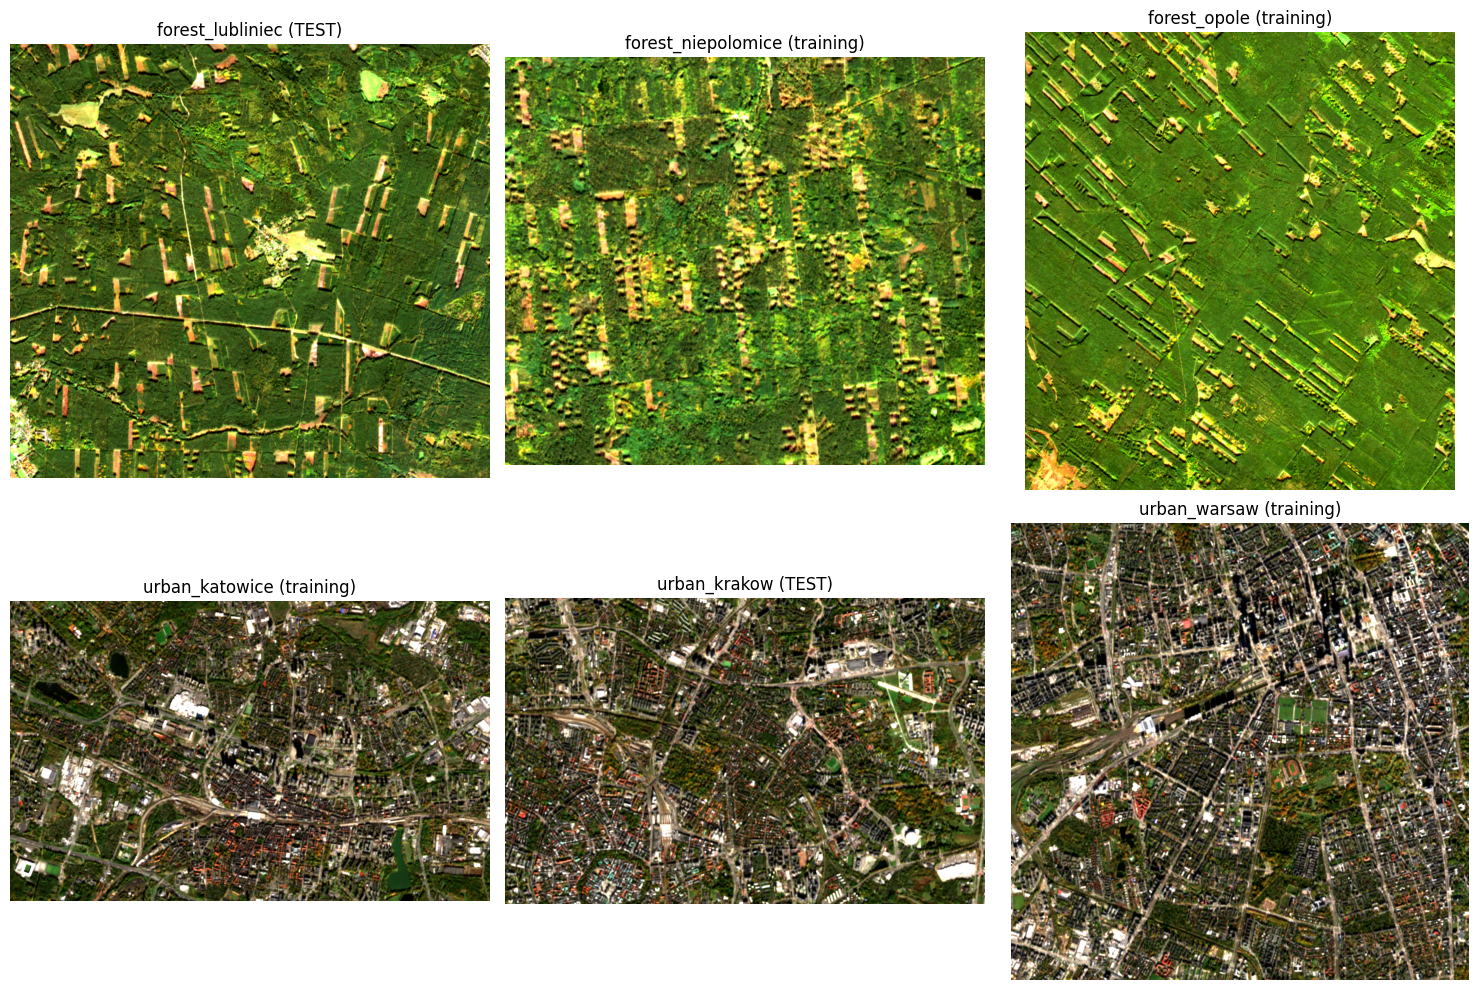

In [5]:
def to_rgb(img, lo=None, hi=None):
    # True color composite (B04, B03, B02) with a contrast stretch, for display only.
    rgb = img[..., [2, 1, 0]]
    if lo is None:
        lo, hi = np.percentile(rgb[rgb > 0], [2, 98])
    return np.clip((rgb - lo) / (hi - lo), 0, 1)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (name, img) in zip(axes.flat, locations.items()):
    ax.imshow(to_rgb(img))
    role = "TEST" if name in TEST_LOCATIONS else "training"
    ax.set_title(f"{name} ({role})")
    ax.axis('off')
plt.tight_layout()
plt.show()

## Question 2: Creating the training data

Each location is cut into patches of 32 × 32 pixels with a step of 16 pixels. Each patch gets the label of its location: 0 for forest and 1 for urban. Patches containing no-data pixels (all bands equal to 0) are discarded, and at most 500 patches are randomly selected from each location, so that all locations contribute equally.

For training patches each patch is rotated by 0°, 90°, 180° and 270° and mirrored, which gives 8 versions of every patch. (A rotated forest is still a forest). This multiplies the number of training examples without downloading new data. The test patches are kept original.

Finally, the pixel values are standardized. From each band, its mean is subtracted and the result is divided by its standard deviation, both computed from the training patches only. Neural networks learn poorly from large, unscaled values, as the diode example from the class notebook shown.

In [7]:
rng = np.random.default_rng(SEED)

def extract_patches(img):
    # Cuts the image into patches
    H, W, _ = img.shape
    patches = np.array([img[r:r + PATCH, c:c + PATCH]
                        for r in range(0, H - PATCH + 1, STRIDE)
                        for c in range(0, W - PATCH + 1, STRIDE)])
    nodata = (patches == 0).all(axis=-1).any(axis=(1, 2))   # pixels with 0 in all bands
    return patches[~nodata]

def augment(patches):
    # Returns 8 versions of every patch: 4 rotations, each also mirrored.
    out = []
    for k in range(4):
        rotated = np.rot90(patches, k, axes=(1, 2))
        out += [rotated, rotated[:, :, ::-1]]
    return np.concatenate(out)

def build_set(names, augment_data):
    X, y = [], []
    for name in names:
        p = extract_patches(locations[name])
        if len(p) > MAX_PATCHES:
            p = p[rng.choice(len(p), MAX_PATCHES, replace=False)]
        print(f"  {name:20} {len(p):5d} patches")
        if augment_data:
            p = augment(p)
        X.append(p)
        y.append(np.full(len(p), int(name.startswith("urban"))))
    return np.concatenate(X), np.concatenate(y)

train_names = [n for n in locations if n not in TEST_LOCATIONS]
print("Training locations:")
X_train_raw, y_train = build_set(train_names, AUGMENT)
print("Test locations:")
X_test_raw, y_test = build_set(TEST_LOCATIONS, False)

print(f"\nTraining set: {len(y_train)} patches (forest {np.sum(y_train == 0)}, urban {np.sum(y_train == 1)})")
print(f"Test set:     {len(y_test)} patches (forest {np.sum(y_test == 0)}, urban {np.sum(y_test == 1)})")

Training locations:
  forest_niepolomice     500 patches
  forest_opole           500 patches
  urban_katowice         500 patches
  urban_warsaw           500 patches
Test locations:
  forest_lubliniec       500 patches
  urban_krakow           500 patches

Training set: 16000 patches (forest 8000, urban 8000)
Test set:     1000 patches (forest 500, urban 500)


In [8]:
# standardization with statistics of the training set only
band_mean = X_train_raw.mean(axis=(0, 1, 2))
band_std = X_train_raw.std(axis=(0, 1, 2))
X_train = ((X_train_raw - band_mean) / band_std).astype(np.float32)
X_test = ((X_test_raw - band_mean) / band_std).astype(np.float32)

# alternative input: 8 features per patch (mean and standard deviation of each band)
def patch_features(X):
    return np.concatenate([X.mean(axis=(1, 2)), X.std(axis=(1, 2))], axis=1)

F_train = patch_features(X_train)
F_test = patch_features(X_test)

print("Pixel input:  ", X_train.shape[1:], "=", np.prod(X_train.shape[1:]), "values per patch")
print("Feature input:", F_train.shape[1:], "values per patch")

Pixel input:   (32, 32, 4) = 4096 values per patch
Feature input: (8,) values per patch


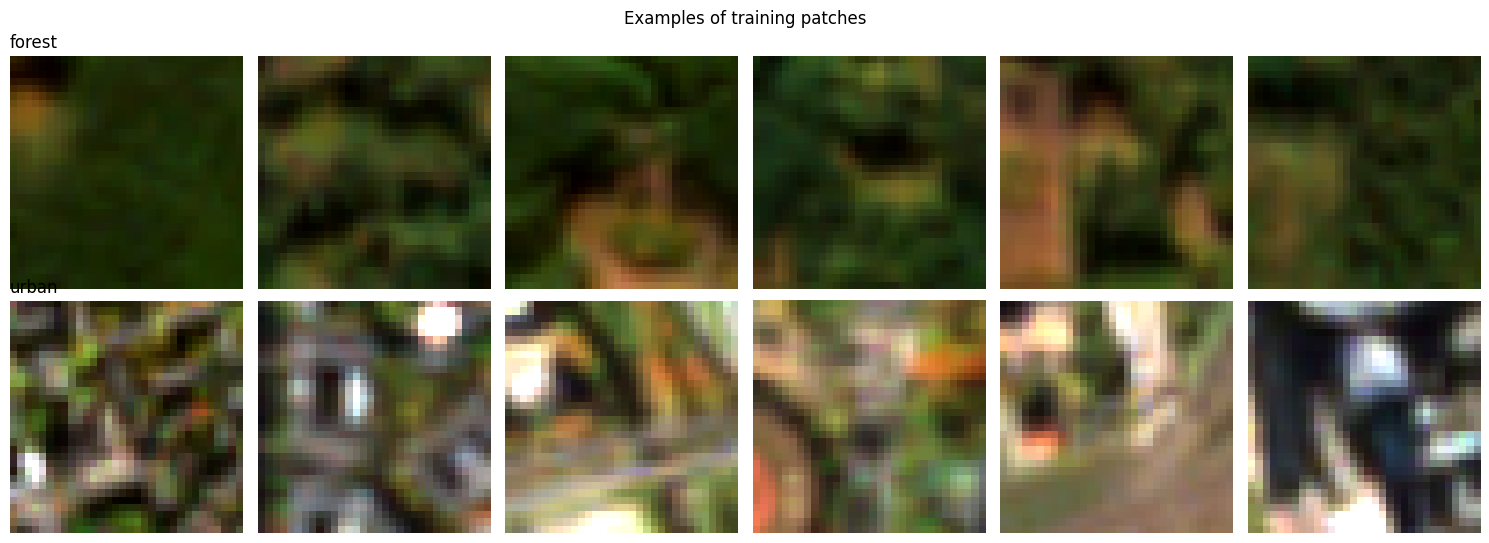

In [10]:
# examples of training patches
lo, hi = np.percentile(X_train_raw[..., [2, 1, 0]], [2, 98])
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for row, cls in enumerate([0, 1]):
    idx = rng.choice(np.where(y_train == cls)[0], 6, replace=False)
    for ax, i in zip(axes[row], idx):
        ax.imshow(to_rgb(X_train_raw[i], lo, hi))
        ax.axis('off')
    axes[row, 0].set_title(["forest", "urban"][cls], loc='left')
plt.suptitle("Examples of training patches")
plt.tight_layout()
plt.show()

## Question 3: The simplest architecture

The simplest network suitable for this problem has three parts:

- Input: the 32 * 32 * 4 patch, flattened into a single vector of 4,096 values (Flatten).
- One hidden layer: a few dozen neurons (32 in the baseline) with the ReLU activation. The nonlinear activation is essential: without it, the whole network would be a linear function, as in the first, unsuccessful attempt of the diode example.
- Output layer: a single neuron with the sigmoid activation, which outputs a number between 0 and 1, the probability that the patch is urban.

The network is trained with the binary cross-entropy loss, the standard loss for two-class problems, and the Adam optimizer. Even this minimal network has about 130000 weights, because each of the 4096 inputs is connected to each hidden neuron.

In [11]:
def build_model(input_type, hidden=(32,), activation="relu", optimizer="adam", lr=1e-3):
    # Fully connected network: input -> hidden layer(s) -> 1 sigmoid output neuron.
    if input_type == "pixels":
        layers = [tf.keras.Input(shape=X_train.shape[1:]), tf.keras.layers.Flatten()]
    else:
        layers = [tf.keras.Input(shape=F_train.shape[1:])]
    for n in hidden:
        layers.append(tf.keras.layers.Dense(n, activation=activation))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    model = tf.keras.Sequential(layers)
    opt = tf.keras.optimizers.Adam(lr) if optimizer == "adam" else tf.keras.optimizers.SGD(lr)
    model.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy"])
    return model

def run_experiment(name, input_type, epochs=30, **settings):
    # Trains one network configuration and returns its results and training history.
    tf.keras.utils.set_random_seed(SEED)   # same initial weights every run
    Xtr, Xte = (X_train, X_test) if input_type == "pixels" else (F_train, F_test)
    model = build_model(input_type, **settings)
    t0 = time.time()
    hist = model.fit(Xtr, y_train, epochs=epochs, batch_size=64,
                     validation_data=(Xte, y_test), verbose=0)
    elapsed = time.time() - t0
    pred = (model.predict(Xte, verbose=0).ravel() > 0.5).astype(int)
    result = {
        "experiment": name,
        "input": input_type,
        "hidden layers": str(settings.get("hidden", (32,))),
        "activation": settings.get("activation", "relu"),
        "optimizer": f"{settings.get('optimizer', 'adam')} (lr={settings.get('lr', 1e-3)})",
        "parameters": model.count_params(),
        "train acc": hist.history["accuracy"][-1],
        "test acc": (pred == y_test).mean(),
        "test acc forest": (pred[y_test == 0] == 0).mean(),
        "test acc urban": (pred[y_test == 1] == 1).mean(),
        "time [s]": round(elapsed, 1),
    }
    return result, hist

def plot_history(hist, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(hist.history[metric], label="training")
        ax.plot(hist.history["val_" + metric], label="test")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(metric)
        ax.legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

## Question 4: Baseline network

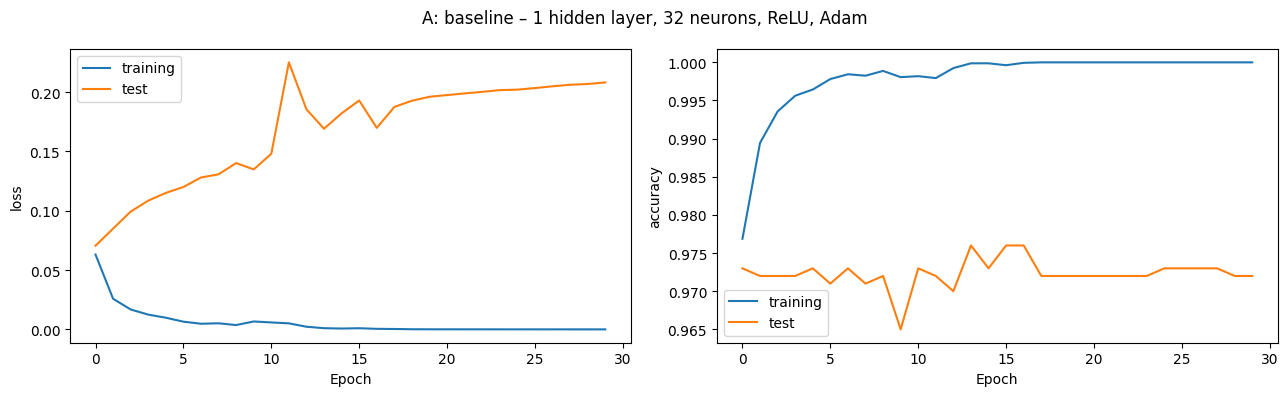

,experiment,input,hidden layers,activation,optimizer,parameters,train acc,test acc,test acc forest,test acc urban,time [s]
0,A: baseline,pixels,"(32,)",relu,adam (lr=0.001),131137,1.0,0.972,0.956,0.988,35.6


In [12]:
baseline, hist_baseline = run_experiment("A: baseline", "pixels", hidden=(32,))
plot_history(hist_baseline, "A: baseline – 1 hidden layer, 32 neurons, ReLU, Adam")
pd.DataFrame([baseline])

Observations – baseline: The simplest network reached a test accuracy of 97.2% on locations it had never seen during training, so it learned to distinguish forest from urban areas rather than memorizing particular places. The training accuracy reached 100%, which shows overfitting: the network classifies all training patches perfectly, but makes a few mistakes on new ones. This is not surprising, as the network has 131137 parameters, more than the number of training patches, so it has enough capacity to memorize the training set.

The learning curves make the overfitting clearly visible. The test accuracy reached about 97% already after the first epoch and did not improve afterwards, so all further training only fitted the training data more closely. At the same time, the training loss dropped to almost zero, while the test loss kept increasing from about 0.07 to 0.21. Since the test accuracy stayed constant, this means that the network became increasingly confident in its predictions, including the wrong ones, which the loss function penalizes strongly. In practice, the training could be stopped after one or two epochs (early stopping) without any loss of accuracy.

The errors are not evenly distributed between the classes: 98.8% of the urban patches but only 95.6% of the forest patches were classified correctly. A likely reason is that the test forest (Lubliniec) differs from the training forests, e.g. in tree species, clearings or forest roads, and some of its patches look more like the urban patches seen during training. Training took 36 seconds.

## Question 5: Permutations of the architecture

Starting from the baseline, one setting is changed at a time, so that its effect can be isolated:

| Experiment | Change compared to the baseline |
|---|---|
| B | more neurons in the hidden layer (256) |
| C | two hidden layers (128 and 32 neurons) |
| D | tanh activation instead of ReLU |
| E | SGD optimizer instead of Adam |
| F | input: 8 patch features instead of 4,096 pixels |
| G | input: 8 patch features, two hidden layers |

In [13]:
experiments = [
    ("B: more nodes",          "pixels",   dict(hidden=(256,))),
    ("C: two hidden layers",   "pixels",   dict(hidden=(128, 32))),
    ("D: tanh activation",     "pixels",   dict(hidden=(32,), activation="tanh")),
    ("E: SGD optimizer",       "pixels",   dict(hidden=(32,), optimizer="sgd", lr=0.01)),
    ("F: patch features",      "features", dict(hidden=(16,))),
    ("G: features, 2 layers",  "features", dict(hidden=(16, 8))),
]

results, histories = [baseline], {"A: baseline": hist_baseline}
for name, input_type, settings in experiments:
    res, hist = run_experiment(name, input_type, **settings)
    results.append(res)
    histories[name] = hist
    print(f"{name:25} test accuracy: {res['test acc']:.1%}")

B: more nodes             test accuracy: 96.9%
C: two hidden layers      test accuracy: 97.0%
D: tanh activation        test accuracy: 98.0%
E: SGD optimizer          test accuracy: 98.1%
F: patch features         test accuracy: 97.0%
G: features, 2 layers     test accuracy: 97.1%


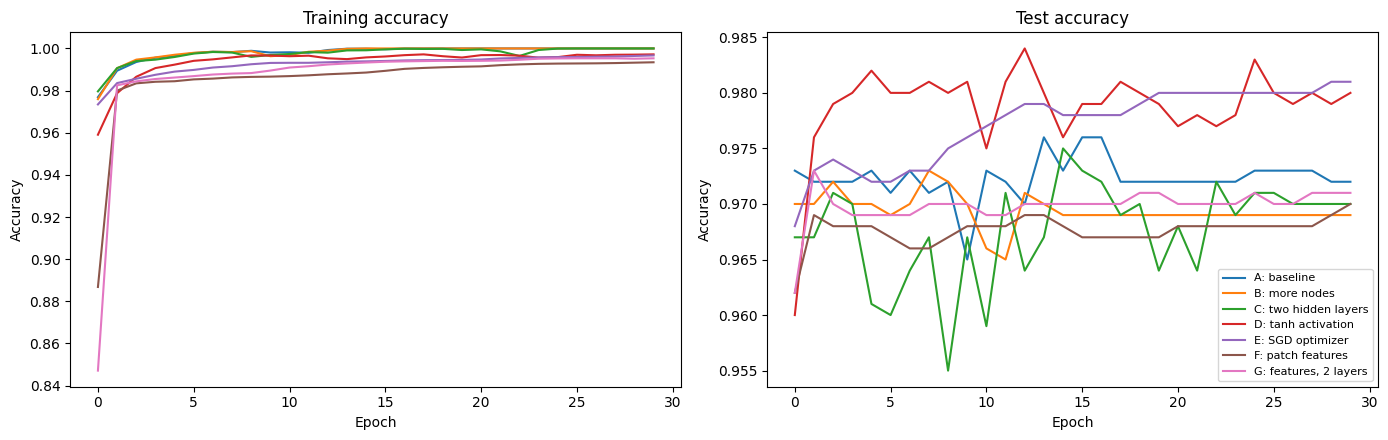

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, hist in histories.items():
    axes[0].plot(hist.history["accuracy"], label=name)
    axes[1].plot(hist.history["val_accuracy"], label=name)
axes[0].set_title("Training accuracy")
axes[1].set_title("Test accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Summary of all experiments

In [16]:
summary = pd.DataFrame(results).set_index("experiment")
summary.style.format({"train acc": "{:.1%}", "test acc": "{:.1%}", "test acc forest": "{:.1%}",
                      "test acc urban": "{:.1%}", "parameters": "{:,}"}, na_rep="–")

,input,hidden layers,activation,optimizer,parameters,train acc,test acc,test acc forest,test acc urban,time [s]
experiment,,,,,,,,,,
A: baseline,pixels,"(32,)",relu,adam (lr=0.001),"131,137",100.0%,97.2%,95.6%,98.8%,35.600000
B: more nodes,pixels,"(256,)",relu,adam (lr=0.001),"1,049,089",100.0%,96.9%,95.6%,98.2%,127.400000
C: two hidden layers,pixels,"(128, 32)",relu,adam (lr=0.001),"528,577",100.0%,97.0%,95.6%,98.4%,69.200000
D: tanh activation,pixels,"(32,)",tanh,adam (lr=0.001),"131,137",99.7%,98.0%,98.0%,98.0%,37.900000
E: SGD optimizer,pixels,"(32,)",relu,sgd (lr=0.01),"131,137",99.7%,98.1%,97.0%,99.2%,29.200000
F: patch features,features,"(16,)",relu,adam (lr=0.001),161,99.3%,97.0%,95.2%,98.8%,15.800000
"G: features, 2 layers",features,"(16, 8)",relu,adam (lr=0.001),289,99.5%,97.1%,95.6%,98.6%,16.000000


### Findings

* All seven networks reached a very similar test accuracy, between 96.9% and 98.1%, which shows that the forest-urban classification is an easy problem for an ANN. The differences between most experiments are small, and the test accuracy fluctuates by about +/- 0.5–1 percentage point between epochs, so differences of a few tenths of a percent (A, B, C, F and G, all between 96.9% and 97.1%) should not be overinterpreted. Since each configuration was trained only once, some of the differences may also be due to chance.

* More nodes and more layers did not help. Increasing the hidden layer from 32 to 256 neurons (B) multiplied the number of parameters by eight (to over a million) and the training time by more than three (127 s), without improving the accuracy (96.9%). Adding a second hidden layer (C) gave the same accuracy (97.0%), but the most unstable test curve, with drops down to 95.5%. All three ReLU networks trained on pixels with Adam (A, B, C) reached 100% training accuracy, so the additional capacity was only used to memorize the training data.

* Changing the activation function or the optimizer gave the best results.The tanh activation (D) and the SGD optimizer (E) reached the highest test accuracies, 98.0% and 98.1%, mainly thanks to better recognition of the forest (98.0% and 97.0% compared to 95.6% in the baseline). Both networks also had a slightly lower training accuracy (99.7%), meaning that they overfitted less. SGD learns more slowly and steadily than Adam, which is visible as a smooth, gradually rising test curve, and this slower fitting seems to act as a form of regularization.

* Eight features are as good as 4096 pixels. The networks using only the mean and standard deviation of each band (F and G) reached 97.0–97.1%, the same as the baseline, with just 161 and 289 parameters instead of 131137, and trained in about 16 seconds. They also overfitted the least (training accuracy 99.3–99.5%). This shows that the spectral properties of the patch carry almost all the information needed for this task, and the spatial arrangement of pixels adds very little.

### Conclusions: why prefer a Bayes classifier when possible?

* The experiments show that even the simplest network solves the forest-urban classification with about 97% accuracy on completely new locations, and that making the network larger does not improve the results, but only increases the training time and the tendency to overfit. The baseline reached its final test accuracy already after the first epoch, and all further training only made it memorize the training data more closely. The best results were achieved not by increasing the network size, but by changing how it learns (tanh activation, SGD optimizer), and a network with 161 parameters performed as well as one with over a million.

* This explains why a Bayesian classifier is preferred whenever it can be applied. In Lab03, a Bayes classifier with only 16 parameters (the mean and standard deviation of each band for each class) separated forest from urban pixels with high accuracy. Such a classifier is trained instantly, its decisions are easy to interpret (e.g. a single threshold in one band), and it does not require choosing an architecture, an optimizer or the number of epochs by trial and error. Since the problem is simple and the classes differ mainly in their spectral properties, which is exactly what the Bayes classifier models, a neural network brings no real advantage here. Neural networks become worthwhile for problems that are too complex to be described by a simple statistical model and for which large amounts of training data are available.